#### Exercisoe 02: ANN for classification

<ul>
<li>Dataset Name: Heart Failure Prediction Dataset</li>
<li>Dataset Link: https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction?resource=download </li>

</ul>

##### Imports

In [344]:
# pip install scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics

# pip install tensorflow
import tensorflow as tf
import keras
from keras import layers

# encoders
from sklearn.preprocessing import LabelEncoder

# classification metrics
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score


#### Load the Dataset

In [345]:
# load the data
df = pd.read_csv("heart.csv")

In [346]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


#### Cleanup the Dataset

In [347]:
# Check total no of records
df.shape

(918, 12)

In [348]:
# check duplicates and missing values
df.duplicated().sum()

np.int64(0)

In [349]:
# do we have missing values? apparently not
# dataset can't have any missing values when passing the data
# to the machine learning algorithm
df.isna().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [350]:
# Check value counts for Sex before modifying 
df['Sex'].value_counts()

Sex
M    725
F    193
Name: count, dtype: int64

In [351]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [352]:
# mapping the Sex variable into binary format (0 and 1)
# Gender 

target_mapping = {
    "M": 1, 
    "F": 0
}

df["Sex"] = df["Sex"].map(target_mapping)
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,0,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,1,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,0,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,1,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [353]:
# Check value counts for ChestPainType before modifying 
df['ChestPainType'].value_counts()

ChestPainType
ASY    496
NAP    203
ATA    173
TA      46
Name: count, dtype: int64

In [354]:
# Check value counts for RestingECG before modifying 
df['RestingECG'].value_counts()

RestingECG
Normal    552
LVH       188
ST        178
Name: count, dtype: int64

In [355]:
# this makes multiple columns with the variable (Separate for yes/no)
from sklearn.preprocessing import OneHotEncoder
variables = ['ChestPainType', 'RestingECG']

# use encoder
encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
one_hot_encoded = encoder.fit_transform(df[variables]).astype(int)
df = pd.concat([df,one_hot_encoded],axis=1).drop(columns=variables)

df.head()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST
0,40,1,140,289,0,172,N,0.0,Up,0,0,1,0,0,0,1,0
1,49,0,160,180,0,156,N,1.0,Flat,1,0,0,1,0,0,1,0
2,37,1,130,283,0,98,N,0.0,Up,0,0,1,0,0,0,0,1
3,48,0,138,214,0,108,Y,1.5,Flat,1,1,0,0,0,0,1,0
4,54,1,150,195,0,122,N,0.0,Up,0,0,0,1,0,0,1,0


In [356]:
# Check value counts for ST_Slope before modifying 
df['ST_Slope'].value_counts()

ST_Slope
Flat    460
Up      395
Down     63
Name: count, dtype: int64

In [357]:
cut_mapper = {'Down': 1, 'Flat': 2,'Up': 3}
df['ST_Slope'] = df['ST_Slope'].map(cut_mapper)
df.head()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST
0,40,1,140,289,0,172,N,0.0,3,0,0,1,0,0,0,1,0
1,49,0,160,180,0,156,N,1.0,2,1,0,0,1,0,0,1,0
2,37,1,130,283,0,98,N,0.0,3,0,0,1,0,0,0,0,1
3,48,0,138,214,0,108,Y,1.5,2,1,1,0,0,0,0,1,0
4,54,1,150,195,0,122,N,0.0,3,0,0,0,1,0,0,1,0


In [358]:
# Check value counts for ExerciseAngina before modifying 
df['ExerciseAngina'].value_counts()

ExerciseAngina
N    547
Y    371
Name: count, dtype: int64

In [359]:
# this just converts the value of column to 0 or 1
# factorize in pandas works too, but only one column at a time
from sklearn.preprocessing import LabelEncoder
variables = ['ExerciseAngina']
encoder = LabelEncoder()
df[variables] = df[variables].apply(encoder.fit_transform)

df.head()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST
0,40,1,140,289,0,172,0,0.0,3,0,0,1,0,0,0,1,0
1,49,0,160,180,0,156,0,1.0,2,1,0,0,1,0,0,1,0
2,37,1,130,283,0,98,0,0.0,3,0,0,1,0,0,0,0,1
3,48,0,138,214,0,108,1,1.5,2,1,1,0,0,0,0,1,0
4,54,1,150,195,0,122,0,0.0,3,0,0,0,1,0,0,1,0


In [360]:
# check the distribution, have a fairly balanced distribution
df['HeartDisease'].value_counts()

HeartDisease
1    508
0    410
Name: count, dtype: int64

<Axes: >

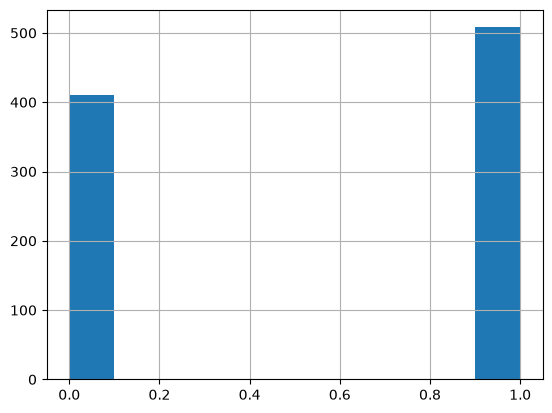

In [361]:
df['HeartDisease'].hist()

#### X/y -split

In [362]:
# perform X/y -split
# if you more than one independent variable, list them all here
# leave out the target variable (dependent variable)

# this is a nice and common trick => everything EXCEPT the target variable => support variables
X = df.drop("HeartDisease", axis=1)

# have only the target variable here (dependent variable)
y_temp = df['HeartDisease']

# since we are doing classification, we have to process our target values with an encoder
# and convert them into a categorical TensorFlow/Keras -format
le = LabelEncoder()
y_enc = le.fit_transform(y_temp)

# convert the label into matrix form
y = tf.keras.utils.to_categorical(y_enc)

# save the categories into a helper list for later purposes
categories = list(le.classes_)
categories

[np.int64(0), np.int64(1)]

#### train/test/validation -split

In [363]:
# in Classic ML, we only had train/test -split
# in deep learning, we usually use validation-data also, for better
# optimization possibilities and better metrics

# unfortunately the scikit-learn's train_test_split doesn't support validation
# set split in itself.

# if you want to split the test set into two for a validation set too, try this trick:

# step 1, split the data into 70% (training data) and 30% (temporary data)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.35)

# step 2, split the temporary data in HALF (0.5) => 15% test and 15% validation
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5)

#### Create the neural network structure

In [364]:
# create neural network

# save the amount of support variables into a helper variable
# so we don't have to update the input_shape all the time
variable_amount = len(X.columns)

# Define Sequential neural network model
# input shape has to match the amount of SUPPORT VARIABLES
# in other words => amount of columns in X 
# Tip: have at least the same number of nodes as in the input shape

# output layer in classification depends on the amounts of
# unique output options in the target variable
model = keras.Sequential(
    [
        layers.BatchNormalization(input_shape=(variable_amount,)),
        layers.Dense(16, activation="relu", kernel_regularizer=keras.regularizers.l1(l1=0.1)),
        layers.Dense(8, activation="relu"),
        layers.Dense(len(categories), activation="softmax")
    ]
)

# select the optimizer and loss function
# for classification, we use categorical crossentropy this time for loss-function
# we also wish to measure the accuracy of our model in the metrics
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()

c:\Users\Gayani\Deep_Learning\Deep_Learning\.venv\Lib\site-packages\keras\src\layers\normalization\batch_normalization.py:181: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ batch_normalization_11          │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 2)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 490 (1.91 KB)

 Trainable params: 458 (1.79 KB)

 Non-trainable params: 32 (128.00 B)

#### Train the next

In [365]:
# train/fit neural network with validation data
# see the instructions on the train/test -split above on how to split the data correctly
model.fit(x=X_train, y=y_train, epochs=300, validation_data=(X_val, y_val))

Epoch 1/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5017 - loss: 6.2987 - val_accuracy: 0.5528 - val_loss: 5.9899
Epoch 2/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6023 - loss: 5.7359 - val_accuracy: 0.5466 - val_loss: 5.7035
Epoch 3/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6879 - loss: 5.2318 - val_accuracy: 0.5528 - val_loss: 5.2175
Epoch 4/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7349 - loss: 4.7863 - val_accuracy: 0.6460 - val_loss: 4.6912
Epoch 5/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7802 - loss: 4.3559 - val_accuracy: 0.7391 - val_loss: 4.1903
Epoch 6/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8020 - loss: 3.9498 - val_accuracy: 0.7578 - val_loss: 3.7614
Epoch 7/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8104 - loss: 3.5534 - val_accuracy: 0.7950 - val_loss: 3.3707
Epoch 8/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8188 - loss: 3.2026 - val_accuracy: 0.7826 - 

#### Error and performance metrics

<Axes: >

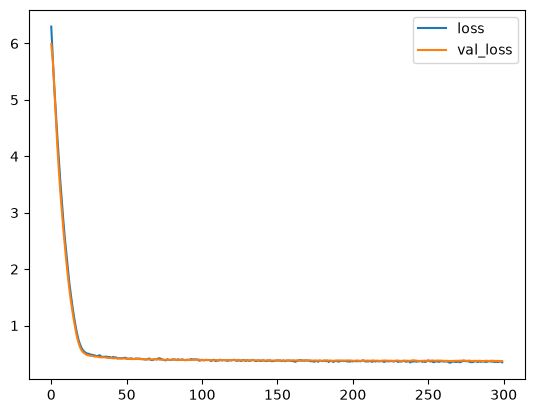

In [366]:
loss_df = pd.DataFrame(model.history.history)
loss_df[['loss', 'val_loss']].plot()

# the model seems to learn fairly well according to loos
# not overfitting, but there's a slight room for improvement

<Axes: >

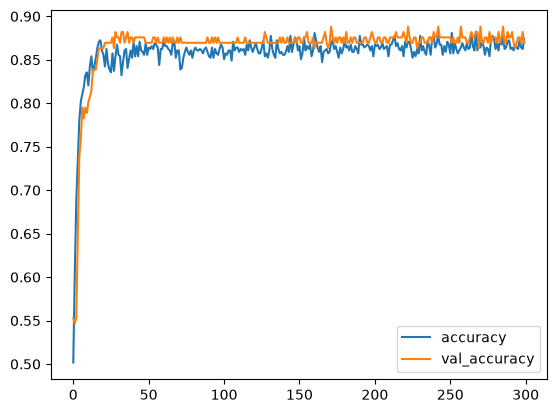

In [367]:
# validation accuracy is fairly high (which is the result from the validation dataset)
# training accuracy is a bit low, but val_accuracy is usually more important to be maximized
# training accuracy being low can imply there's toom for improvement still in the neural network
loss_df[['accuracy', 'val_accuracy']].plot()

In [368]:
# compare the final model loss/evaluation values
# the values should match roughly
print("Test data evaluation:")
print(model.evaluate(X_test, y_test, verbose=0))
print("\nTrain data evaluation:")
print(model.evaluate(X_train, y_train, verbose=0))

# in classification we compare the loss and accuracy values

Test data evaluation:
[0.440855473279953, 0.8322981595993042]

Train data evaluation:
[0.33721429109573364, 0.8808724880218506]


In [369]:
# get predictions and convert with argmax() to get the categories
# instead of RAW probabilites
test_predictions = model.predict(X_test)
test_predictions = np.argmax(test_predictions, axis=1)

# convert also y-test values with argmax
y_test = np.argmax(y_test, axis=1)

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 241ms/step


<Axes: >

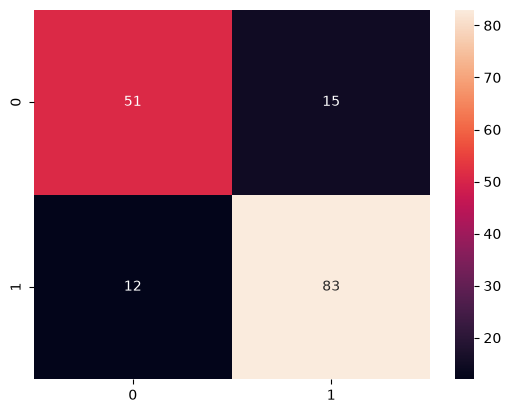

In [370]:
# confusion matrix
sns.heatmap(confusion_matrix(y_test, test_predictions), annot=True, fmt='g',
            xticklabels=categories, yticklabels=categories)

In [371]:
print(classification_report(y_test, test_predictions, target_names=["No heart disease", "Heart disease"]))

                  precision    recall  f1-score   support

No heart disease       0.81      0.77      0.79        66
   Heart disease       0.85      0.87      0.86        95

        accuracy                           0.83       161
       macro avg       0.83      0.82      0.83       161
    weighted avg       0.83      0.83      0.83       161



In [372]:
# The AUC score is a super sensitive metric
# you often get low scores, even 0.5

# in binary classification, AUC values are often interpreted as follows:
# A binary classifier is useful only when it achieves ROC-AUC score greater than 0.5 and as near to 1 as possible. 
# If a classifier yields a score less than 0.5, it simply means that the model is performing worse 
# than a random classifier, and therefore is useless.

# In multi category classification , AUC values are often interpreted as follows: 
# 0.5-0.6 (failed)
# 0.6-0.7 (worthless)
# 0.7-0.8 (poor)
# 0.8-0.9 (good)
# > 0.9 (excellent)

# get ROC-AUC -score
roc_auc_score(y, model.predict(X), multi_class="ovr")

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


0.9332293067025159

#### Try the model in practice with new data

In [373]:
X.columns

Index(['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR',
       'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'ChestPainType_ASY',
       'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA',
       'RestingECG_LVH', 'RestingECG_Normal', 'RestingECG_ST'],
      dtype='str')

In [374]:
df.head(3)

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST
0,40,1,140,289,0,172,0,0.0,3,0,0,1,0,0,0,1,0
1,49,0,160,180,0,156,0,1.0,2,1,0,0,1,0,0,1,0
2,37,1,130,283,0,98,0,0.0,3,0,0,1,0,0,0,0,1


In [378]:
# let's try with some imaginary data
# modify this as needed regarding your own dataset
tester_row = {
    'Age': 54,
    'Sex': 1,                 # M = 1, F = 0
    'RestingBP': 130,
    'Cholesterol': 240,
    'FastingBS': 0,
    'MaxHR': 150,
    'ExerciseAngina': 0,      # use the same encoding as in your data
    'Oldpeak': 1.0,
    'ST_Slope': 1,            # use the same encoding as in your data
    'ChestPainType_ASY': 1,
    'ChestPainType_ATA': 0,
    'ChestPainType_NAP': 0,
    'ChestPainType_TA': 0,
    'RestingECG_LVH': 0,
    'RestingECG_Normal': 1,
    'RestingECG_ST': 0
}

# convert to pandas-format, same column order as the training data
tester_row = pd.DataFrame([tester_row])
result = model.predict(tester_row)[0]

labels = ["No heart disease", "Heart disease"]
result_text = labels[np.argmax(result)]

# switch to decimal representation
np.set_printoptions(precision=9, suppress=True)

print(f"Has heart disease?: {result_text}")
print()
print("Probabilities by class:")
print(labels)
print(result)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Has heart disease?: Heart disease

Probabilities by class:
['No heart disease', 'Heart disease']
[0.1392368 0.8607632]
